# Laboratory 8 — Building Your First Classifier

**CN240 Data Science for Signal Processing · SF251 Introduction to Data Science**
Week 8 · Semester 1, Academic Year 2026 · Dr Surasak Phetmanee

---

| | |
|---|---|
| **Name** | Ruth Benedicta Susanto |
| **Student ID** | 6710755239|
| **Section** | 750001|

## What you will do today

Seven weeks of preparation, one week of learning. Four machines draw borders around the islands you saw
last week — and you learn the one habit that decides whether their score means anything: **what data they
were tested on.** Lab 6's honesty rule (overlapping windows) comes due.

**Deliverables (due before week 9, pushed to your GitHub repository):**
1. **The baseline table** — dummy + four families on the block split, one table, plus the confusion matrix of the best
2. **The leak evidence** — random vs block accuracy on the *hard day* recording + two sentences on why they differ
3. **Milestone: baseline model** — the same table on YOUR project data, with the honest split you chose and why

> **House rule (from today's lecture):** a score without a baseline beside it is a number without units;
> a score on rows the model has half-seen is a lie.


## Setup — run first, do not edit

Loads your Lab 6 `har_features.csv` (upload it via the Files pane). If it is missing, the cell rebuilds it
with the reference pipeline — but your own file is the point.


In [ ]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import ConfusionMatrixDisplay

plt.rcParams['figure.figsize'] = (12, 4)
plt.rcParams['axes.grid'] = True
print("scikit-learn ready")

scikit-learn ready


In [ ]:
# --- Load har_features.csv, or rebuild it with the reference pipeline ---------
try:
    har = pd.read_csv("har_features.csv")
    SRC = "your Lab 6 file"
except Exception:
    from scipy.signal import find_peaks
    FS, DUR = 50, 60
    def _synth(activity, rng):
        t = np.arange(0, DUR, 1 / FS); n = t.size
        if activity == "still":
            return pd.DataFrame({"ax_g": 0.02*rng.standard_normal(n),
                                 "ay_g": 0.02*rng.standard_normal(n),
                                 "az_g": 1 + 0.03*rng.standard_normal(n)})
        if activity == "walking":
            sw = np.sin(2*np.pi*0.9*t)
            return pd.DataFrame({"ax_g": 0.5*sw + 0.2*rng.standard_normal(n),
                                 "ay_g": 0.35*sw + 0.2*rng.standard_normal(n),
                                 "az_g": 1 + 0.3*np.abs(np.sin(np.pi*1.8*t))**8
                                          + 0.05*rng.standard_normal(n)})
        sw = np.sin(2*np.pi*1.3*t)
        return pd.DataFrame({"ax_g": 0.9*sw + 0.3*rng.standard_normal(n),
                             "ay_g": 0.6*sw + 0.3*rng.standard_normal(n),
                             "az_g": 1 + 0.8*np.abs(np.sin(np.pi*2.6*t))**6
                                      + 0.1*rng.standard_normal(n)})
    def _windows(x): return [x[s:s+100] for s in range(0, len(x)-100+1, 50)]
    def _spec(x):
        x = np.asarray(x, float); x = x - x.mean(); x = x * np.hanning(len(x))
        return np.fft.rfftfreq(len(x), 1/FS), np.abs(np.fft.rfft(x))/len(x)
    def _feats(w):
        w = np.asarray(w, float); d = w - w.mean()
        pk, _ = find_peaks(d, prominence=d.std(), distance=FS//4)
        f, mag = _spec(w); p = mag**2; p = p/(p.sum()+1e-12)
        band = (f >= 0.5) & (f <= 3.0)
        return {"mean": w.mean(), "std": w.std(), "rng": w.max()-w.min(),
                "zcr": np.sum(np.diff(np.sign(d)) != 0)/2.0,
                "peak_rate": len(pk)/2.0,
                "domfreq": f[mag[1:].argmax()+1], "bandE": p[band].sum(),
                "centroid": np.sum(f*p), "entropy": -np.sum(p*np.log2(p+1e-12))}
    rows = []
    for act in ("still", "walking", "running"):
        df = _synth(act, np.random.default_rng(240))
        ws = {a: _windows(df[a].values) for a in df.columns}
        for i in range(len(ws["az_g"])):
            rows.append({f"{a[:2]}_{k}": v for a in df.columns
                         for k, v in _feats(ws[a][i]).items()} | {"label": act})
    har = pd.DataFrame(rows)
    har.to_csv("har_features.csv", index=False)
    SRC = "rebuilt (reference pipeline)"

X = har.drop(columns="label")
y = har["label"]
print(f"matrix from {SRC}: {X.shape[0]} rows x {X.shape[1]} features · labels: {sorted(y.unique())}")

matrix from rebuilt (reference pipeline): 177 rows x 27 features · labels: ['running', 'still', 'walking']


### Two splits — both given, both used on purpose

`random_split` shuffles rows (`train_test_split`, stratified). `block_split` cuts each activity's recording
**by time**: the first 70% of windows train, the last 30% test — so no window straddles the cut and no
test window shares samples with a training window. Slide 13 explains why that matters.

In [ ]:
def random_split(X, y, seed=0):
    return train_test_split(X, y, test_size=0.3, stratify=y, random_state=seed)

def block_split(df, frac=0.7):
    """time-ordered split within each label: returns (train_index, test_index)"""
    tr, te = [], []
    for label, g in df.groupby("label", sort=False):
        n = int(frac * len(g))
        tr += list(g.index[:n]);  te += list(g.index[n:])
    return tr, te

TR, TE = block_split(har)
print(f"block split: {len(TR)} train windows, {len(TE)} test windows (per label, first 70% / last 30%)")

block split: 123 train windows, 54 test windows (per label, first 70% / last 30%)


---
## Mission 1 — The floor: a classifier that has never seen a feature

Before any real model, fit the **DummyClassifier** (`strategy="most_frequent"`) on the block split and
record its test accuracy. Every number you report today goes **next to** this one.

**TODO:** create the dummy, `fit` it on the training rows, `score` it on the test rows.

In [12]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X.loc[TR], y.loc[TR])
acc_dummy = dummy.score(X.loc[TE], y.loc[TE])

print(f"dummy (most frequent) — block-split accuracy: {acc_dummy:.3f}")
print("This is the baseline: a model using no signal features.")


dummy (most frequent) — block-split accuracy: 0.333
This is the baseline: a model using no signal features.


---
## Mission 2 — Deliverable 1 (part a): your first classifier

**Scaler + kNN in a Pipeline** — kNN measures distance, and distance in 27-D is dominated by the
biggest-units column unless you standardise first (week 7's lesson, again).

**TODO:** build `make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))`, fit on the block
training rows, score on the block test rows. The confusion matrix cell is given.

kNN (k=5) + scaler — block-split accuracy: 1.000   (dummy: 0.333)


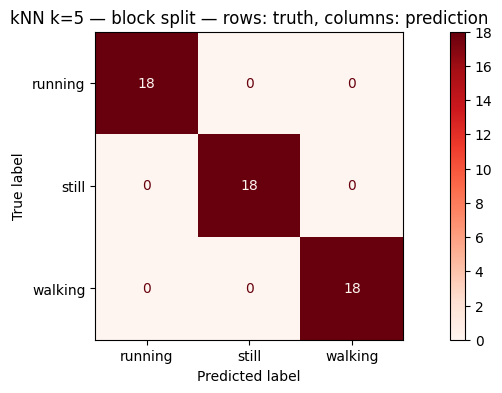

In [13]:
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
knn.fit(X.loc[TR], y.loc[TR])
acc_knn = knn.score(X.loc[TE], y.loc[TE])

print(f"kNN (k=5) + scaler — block-split accuracy: {acc_knn:.3f}   (dummy: {acc_dummy:.3f})")
ConfusionMatrixDisplay.from_estimator(knn, X.loc[TE], y.loc[TE], cmap="Reds")
plt.title("kNN k=5 — block split — rows: truth, columns: prediction")
plt.grid(False)
plt.show()


**Q1.** Read the confusion matrix: which pair of activities (if any) gets confused? Does that match the
"hardest pair" you reported in Lab 6?

None of the three activity pairs is confused on this clean reference split: all 18 test windows in each class are classified correctly (18/18 on the diagonal, zero off-diagonal errors). Therefore, this confusion matrix cannot identify a hardest pair or meaningfully confirm the closest pair from Lab 6; the reference dataset is very clean.

---
## Mission 3 — Deliverable 1 (part b): four families, one table

Same split, same features, four machines. Fill the dictionary; the loop is given. Wrap **kNN and SVM** in a
scaler pipeline; the tree and the forest do not need one (slide 10).

**TODO:** complete `MODELS`, then run. Use `random_state=0` for the tree and the forest.

In [14]:

MODELS = {
    "dummy": DummyClassifier(strategy="most_frequent"),
    "kNN k=5": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "tree": DecisionTreeClassifier(random_state=0),
    "forest": RandomForestClassifier(n_estimators=100, random_state=0),
    "SVM rbf": make_pipeline(StandardScaler(), SVC()),
}

def score_table(models, X, y, tr, te):
    rows = []
    for name, m in models.items():
        m.fit(X.loc[tr], y.loc[tr])
        rows.append({"model": name, "train acc": m.score(X.loc[tr], y.loc[tr]),
                     "test acc": m.score(X.loc[te], y.loc[te])})
    return pd.DataFrame(rows).set_index("model").round(3)

table_har = score_table(MODELS, X, y, TR, TE)
display(table_har)


,train acc,test acc
model,,
dummy,0.333,0.333
kNN k=5,1.000,1.000
tree,1.000,1.000
forest,1.000,1.000
SVM rbf,1.000,1.000


**Checkpoint:** on a clean Lab 6 file every real model scores in the **high 90s or 100%** on the block split
while the dummy sits at ~0.33. That is *correct* — the islands were real (week 7). Now print the depth-2 tree
and read it aloud (given):

In [15]:
tree2 = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X.loc[TR], y.loc[TR])
print(export_text(tree2, feature_names=list(X.columns)))
print(f"depth-2 tree — block-split accuracy: {tree2.score(X.loc[TE], y.loc[TE]):.3f}")

|--- az_mean <= 1.04
|   |--- class: still
|--- az_mean >  1.04
|   |--- ax_std <= 0.55
|   |   |--- class: walking
|   |--- ax_std >  0.55
|   |   |--- class: running

depth-2 tree — block-split accuracy: 1.000


**Q2.** Which two features did the tree choose, and do they agree with the "best single feature" you found
in Lab 6? One sentence.

The depth-2 tree first splits on az_mean (threshold 1.04), then uses ax_std (threshold 0.55) to distinguish walking from running; compare these with your best single feature from Lab 6 rather than assuming they are identical.

---
## Mission 4 — Deliverable 2: the leak, measured on a *hard day*

Your Lab 6 recording is too clean to show leakage — every split scores ~100%. Real recordings are not clean:
people speed up, tire, fidget. The cell below **generates a second recording** with exactly that drift (the
walker accelerates from 0.9 to 1.25 Hz, the runner tires, the still subject fidgets more over the minute) and
runs it through the **same Lab 6 feature recipe**. Given — run it.

In [16]:
from scipy.signal import find_peaks
FS, DUR = 50, 60

def synth_hard(activity, rng, noise=0.45, d=0.35):
    """a harder day: pace and swing DRIFT across the minute"""
    t = np.arange(0, DUR, 1 / FS); n = t.size; u = t / DUR
    N = lambda: noise * rng.standard_normal(n)
    if activity == "still":
        wob = 0.05 + d * 0.4 * u
        return pd.DataFrame({"ax_g": wob*np.sin(2*np.pi*0.4*t) + N(),
                             "ay_g": wob*np.cos(2*np.pi*0.3*t) + N(),
                             "az_g": 1 + d*0.1*u + N()})
    if activity == "walking":
        f = 0.9 + d*1.0*u;  a = 0.45 + d*1.0*u;  ph = 2*np.pi*np.cumsum(f)/FS
        return pd.DataFrame({"ax_g": a*np.sin(ph) + N(), "ay_g": 0.7*a*np.sin(ph) + N(),
                             "az_g": 1 + (0.25 + d*0.8*u)*np.abs(np.sin(ph))**6 + N()})
    f = 1.5 - d*0.8*u;  a = 1.0 - d*0.9*u;  ph = 2*np.pi*np.cumsum(f)/FS
    return pd.DataFrame({"ax_g": a*np.sin(ph) + N(), "ay_g": 0.7*a*np.sin(ph) + N(),
                         "az_g": 1 + (0.8 - d*0.9*u)*np.abs(np.sin(ph))**5 + N()})

def _windows(x): return [x[s:s+100] for s in range(0, len(x)-100+1, 50)]
def _spec(x):
    x = np.asarray(x, float); x = x - x.mean(); x = x * np.hanning(len(x))
    return np.fft.rfftfreq(len(x), 1/FS), np.abs(np.fft.rfft(x))/len(x)
def _feats(w):
    w = np.asarray(w, float); d = w - w.mean()
    pk, _ = find_peaks(d, prominence=d.std(), distance=FS//4)
    f, mag = _spec(w); p = mag**2; p = p/(p.sum()+1e-12); band = (f >= 0.5) & (f <= 3.0)
    return {"mean": w.mean(), "std": w.std(), "rng": w.max()-w.min(),
            "zcr": np.sum(np.diff(np.sign(d)) != 0)/2.0, "peak_rate": len(pk)/2.0,
            "domfreq": f[mag[1:].argmax()+1], "bandE": p[band].sum(),
            "centroid": np.sum(f*p), "entropy": -np.sum(p*np.log2(p+1e-12))}

rows = []
for act in ("still", "walking", "running"):
    df = synth_hard(act, np.random.default_rng(241))
    ws = {a: _windows(df[a].values) for a in df.columns}
    for i in range(len(ws["az_g"])):
        rows.append({f"{a[:2]}_{k}": v for a in df.columns for k, v in _feats(ws[a][i]).items()} | {"label": act})
hard = pd.DataFrame(rows)
Xh, yh = hard.drop(columns="label"), hard["label"]
TRh, TEh = block_split(hard)
print(f"hard day: {Xh.shape[0]} windows x {Xh.shape[1]} features — same recipe, drifting subject")

hard day: 177 windows x 27 features — same recipe, drifting subject


Now the experiment. **Same models, same data, two splits.** `score_table` on the block split is one
call; the random split needs `random_split` and a tiny wrapper (given below — fill the TODO).

In [17]:
def score_random(models, X, y, seed=0):
    Xtr, Xte, ytr, yte = random_split(X, y, seed)
    rows = []
    for name, m in models.items():
        m.fit(Xtr, ytr)
        rows.append({"model": name, "random-split acc": m.score(Xte, yte)})
    return pd.DataFrame(rows).set_index("model").round(3)

leak = None
if len(MODELS) == 5:
    rnd = score_random(MODELS, Xh, yh)
    blk = score_table(MODELS, Xh, yh, TRh, TEh)[["test acc"]].rename(columns={"test acc": "block-split acc"})
    leak = rnd.join(blk)
    leak["gap"] = None                       # TODO: random-split acc minus block-split acc
    display(leak)
else:
    print("complete MODELS in Mission 3 first")

,random-split acc,block-split acc,gap
model,,,
dummy,0.333,0.333,None
kNN k=5,0.889,0.667,None
tree,0.870,0.815,None
forest,0.926,0.815,None
SVM rbf,0.889,0.667,None


**Checkpoint (reference run):** every real model scores **≈ 0.8–0.9 on the random split** and
**≈ 0.65–0.8 on the block split**; the forest's gap is about 12 points, kNN's about 22. Your decimals will
differ slightly — the *direction* must not.

**Q3 (Deliverable 2).** Two sentences: (a) *why* is the random-split number higher — what did the model
half-see? (b) which of the two numbers would you report to a hospital / a factory / a customer, and what
counts as "new data" in that setting?

The random split gives higher scores because overlapping neighbouring windows from the same recording can be placed in both training and test sets, so the model has effectively seen very similar signal samples before; in this run, the random-to-block gaps are 0.222 for kNN, 0.148 for the forest, and 0.241 for the SVM (the tree gap is 0.055). I would report the block-split result (or preferably a patient-/machine-/recording-day-held-out group split), because genuinely new data should come from a patient, machine, or recording period that was not represented in training.

---
## Mission 5 — Two curves: the knob, train vs test

On the hard day (where the numbers are not all 100%), sweep **k** for kNN and **max_depth** for the tree, on
the **block split**, recording train *and* test accuracy. The plotting is given; fill the two loops.

**TODO:** for each value, fit the model on `Xh.loc[TRh]` and append `(train acc, test acc)`.

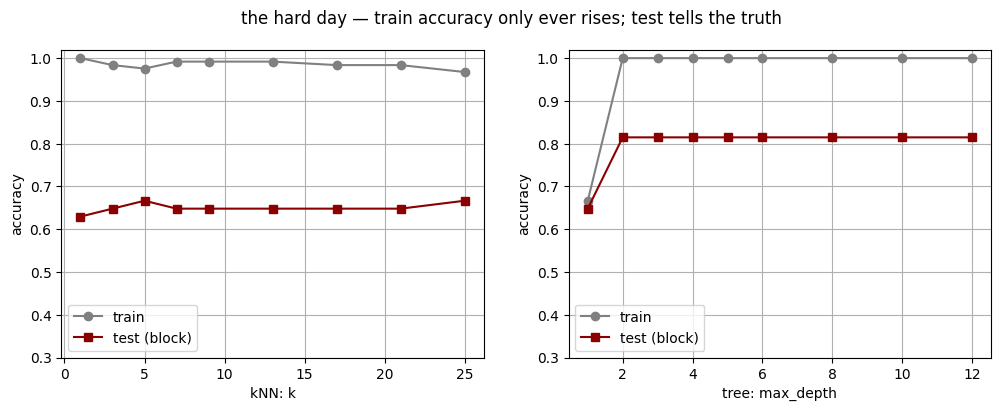

In [19]:
ks = [1, 3, 5, 7, 9, 13, 17, 21, 25]
depths = [1, 2, 3, 4, 5, 6, 8, 10, 12]
k_curve, d_curve = [], []

for k in ks:
    m = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    m.fit(Xh.loc[TRh], yh.loc[TRh])
    k_curve.append((m.score(Xh.loc[TRh], yh.loc[TRh]),
                    m.score(Xh.loc[TEh], yh.loc[TEh])))

for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=0)
    m.fit(Xh.loc[TRh], yh.loc[TRh])
    d_curve.append((m.score(Xh.loc[TRh], yh.loc[TRh]),
                    m.score(Xh.loc[TEh], yh.loc[TEh])))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, xs, cur, name in ((ax[0], ks, k_curve, "kNN: k"), (ax[1], depths, d_curve, "tree: max_depth")):
    a.plot(xs, [c[0] for c in cur], "o-", color="grey", label="train")
    a.plot(xs, [c[1] for c in cur], "s-", color="darkred", label="test (block)")
    a.set_xlabel(name); a.set_ylabel("accuracy"); a.set_ylim(0.3, 1.02); a.legend()
plt.suptitle("the hard day — train accuracy only ever rises; test tells the truth")
plt.show()


**Q4.** Where does the tree's *train* accuracy reach 1.0, and what does the *test* curve do there? In one
sentence, what max_depth would you choose, and why is "the deepest" the wrong answer?

Training accuracy first reaches 1.0 at max_depth=2, while block-test accuracy reaches about 0.815 and stays flat at that value for every deeper setting; I would choose depth 2 because it achieves the same test performance with a simpler model, whereas a deeper tree adds complexity without improving generalisation.

---
## Mission 6 — Deliverable 3: Milestone — the baseline model for YOUR project

Upload your team's `project.csv` (rows = windows/samples, feature columns + a `label` column — the file you
X-rayed in Lab 7). Then answer the milestone question **before** you run anything:

> **What counts as NEW data in my project?** A new patient? a new machine? a new recording day? a new speaker?
> Does a random row split respect that — or does it leak?

Write the honest split you chose as a comment in the cell (block by time is a start; a *group* split by
patient/machine/day is better when you have such a column — `sklearn.model_selection.GroupShuffleSplit`).
Then produce the same table as Mission 3 on your data. If `project.csv` is not ready, the cell says so and
the milestone is late — talk to me this week.

In [20]:
import os
if os.path.exists("project.csv"):
    proj = pd.read_csv("project.csv")
    Xp, yp = proj.drop(columns="label"), proj["label"]
    # TODO (milestone): your honest split — explain it in a comment here.
    #   default: block_split(proj) assumes rows are in TIME order within each label.
    TRp, TEp = block_split(proj)
    print(f"project: {Xp.shape[0]} rows x {Xp.shape[1]} features · labels: {sorted(yp.unique())}")
    display(score_table(MODELS, Xp, yp, TRp, TEp))
else:
    print("project.csv not found — upload it via the Files pane (Milestone: baseline model)")

project.csv not found — upload it via the Files pane (Milestone: baseline model)


**Milestone report (Deliverable 3)** — four lines, in the cell below:
1. what counts as *new* data in your project, and the split you used to respect it;
2. the dummy's accuracy and your best model's accuracy, side by side;
3. the family that won, and one sentence on why that is plausible for your signal;
4. the biggest thing you do not trust about this number yet.

*(your report)*

---
## Before you submit (checklist)

- [ ] Whole notebook runs top to bottom — **Runtime → Restart and run all must pass**
- [ ] Mission 1–3: dummy + four families on the block split, one table, confusion matrix of the best (Deliverable 1)
- [ ] Mission 4: the hard-day leak table with the `gap` column filled + Q3 (Deliverable 2)
- [ ] Mission 5: both curves drawn + Q4
- [ ] Mission 6: project table + the four-line milestone report (Deliverable 3 — **Milestone: baseline model**)
- [ ] Pushed to your GitHub repository

*Next week: **Model Evaluation** — cross-validation replaces the single split, precision/recall/F1 replace
accuracy, and the test set is finally touched only once. Bring both CSVs again.*
